In [26]:
from pathlib import Path
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# 1) Importação do Dataset

**Sobre o Dataset**: Este conjunto de dados inclui informações sobre as avaliações feitas pelos clientes.
Depois que um dataset comprar um produto na Olist Store, o vendedor é notificado para processar o pedido. Depois
que o cliente receber o produto, ou quando a data de entrega esperada esteja próxima, ele recebe uma pesquisa
de satisfação por e-mail, podendo deixar um comentário sobre a experiência de compra.

**Sobre os Dados**

- **review_id**: Identificador único da review

- **order_id**: Identificador único do pedido

- **review_score**: Nota avaliada sobre o pedido em uma escala de 1 até 5

- **review_comment_title**: Título do comentário deixado pelo cliente

- **review_comment_message**: Mensagem de comentário da avaliação deixada pelo cliente

- **review_creation_date**: Mostra a data em que a pesquisa de satisfação foi enviada ao cliente

- **review_answer_timestamp**: Exibe o registro de data e hora da resposta da pesquisa de satisfação

In [27]:
target_column = 'review_score'

main_directoty = Path.cwd().parent
main_file = main_directoty / "data" / "documents" / "olist_order_reviews_dataset.csv"

In [28]:
df_reviews = pd.read_csv(main_file)
df_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [29]:
df_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [30]:
# Remoção dos espaços em branco das strings
df_reviews['review_id'] = df_reviews['review_id'].str.strip()
df_reviews['order_id'] = df_reviews['order_id'].str.strip()
df_reviews['review_comment_title'] = df_reviews['review_comment_title'].str.strip()
df_reviews['review_comment_message'] = df_reviews['review_comment_message'].str.strip()

# Adaptação das colunas de data de string para datetime
df_reviews['review_creation_date'] = pd.to_datetime(df_reviews['review_creation_date'].str.strip(), format='%Y-%m-%d %H:%M:%S')
df_reviews['review_answer_timestamp'] = pd.to_datetime(df_reviews['review_answer_timestamp'].str.strip(), format='%Y-%m-%d %H:%M:%S')

df_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53


### 1.1) Descrição dos Dados

In [31]:
df_description = pd.DataFrame(data={"Coluna": df_reviews.columns})

df_description["Tipo_Dado"] = df_description["Coluna"].map(df_reviews.dtypes).astype("str")
df_description["Quantidade_Valores_Unicos"] = df_description["Coluna"].map(df_reviews.nunique())
df_description["Quantidade_Duplicadas"] = df_description["Coluna"].apply(lambda c: df_reviews[c].duplicated().sum())

df_description["%_Nulos"] = (df_description["Coluna"].map(df_reviews.isnull().mean()) * 100).round(2)
df_description["É_Constante"] = df_description["Quantidade_Valores_Unicos"].apply(lambda x: x <=  1)

display(df_description)

,Coluna,Tipo_Dado,Quantidade_Valores_Unicos,Quantidade_Duplicadas,%_Nulos,É_Constante
0,review_id,object,98410,814,0.00,False
1,order_id,object,98673,551,0.00,False
2,review_score,int64,5,99219,0.00,False
3,review_comment_title,object,4179,95044,88.34,False
4,review_comment_message,object,35617,63606,58.70,False
5,review_creation_date,datetime64[ns],636,98588,0.00,False
6,review_answer_timestamp,datetime64[ns],98248,976,0.00,False


# 2) Análise de Dados

### 2.1) Avaliação de Duplicadas

Houveram receios das colunas ids ('review_id', 'order_id') apresentarem duplicadas, e foi verificado
que o review_id apresenta quase todos os resultados (exceto o 'order_id') duplicados e
o 'order_id' apresenta resultados diferentes

In [32]:
duplicated_review_id = df_reviews[df_reviews['review_id'].duplicated(keep=False)]

df_duplicated_review = (
    duplicated_review_id.groupby("review_id").agg(
        n_order = ("order_id", "nunique"),
        n_score = ("review_score", "nunique"),
        n_text_message = ("review_comment_message", "nunique")
    ).query("n_order > 1")
)

print(f'reviews_id com múltiplos order_id: {len(df_duplicated_review)}')
display(df_duplicated_review.head(15))

reviews_id com múltiplos order_id: 789


,n_order,n_score,n_text_message
review_id,,,
00130cbe1f9d422698c812ed8ded1919,2,1,1
0115633a9c298b6a98bcbe4eee75345f,2,1,0
0174caf0ee5964646040cd94e15ac95e,2,1,1
017808d29fd1f942d97e50184dfb4c13,2,1,0
0254bd905dc677a6078990aad3331a36,2,1,1
0288d42bef3dfe36930740c9588a570f,2,1,0
02aa7f5f75e964e3c7efa59a1f515281,2,1,0
034528cb00b6bc981847acafbdf2ae0b,2,1,0
03a6a25db577d0689440933055111897,2,1,1


In [33]:
duplicated_order_id = df_reviews[df_reviews['order_id'].duplicated(keep=False)]

df_duplicated_order = (
    duplicated_order_id.groupby("order_id").agg(
        n_review = ("review_id", "nunique"),
        n_score = ("review_score", "nunique"),
        n_text_message = ("review_comment_message", "nunique")
    ).query("n_review > 1")
)

print(f'order_id com múltiplos review_id: {len(df_duplicated_order)}')
display(df_duplicated_order.head(15))

order_id com múltiplos review_id: 547


,n_review,n_score,n_text_message
order_id,,,
0035246a40f520710769010f752e7507,2,1,1
013056cfe49763c6f66bda03396c5ee3,2,2,0
0176a6846bcb3b0d3aa3116a9a768597,2,1,0
02355020fd0a40a0d56df9f6ff060413,2,2,2
029863af4b968de1e5d6a82782e662f5,2,2,0
02e0b68852217f5715fb9cc885829454,2,1,2
02e723e8edb4a123d414f56cc9c4665e,2,1,1
03515a836bb855b03f7df9dee520a8fc,2,1,0
03c939fd7fd3b38f8485a0f95798f1f6,3,2,2


### 2.2) Distribuição de valores

#### 2.2.1) Distribuição por Texto

Será avaliado a volumetria de notas, porém o texto deve estar preenchido para prever o valor da coluna

In [34]:
# Criação de um dataset removendo as duplicadas do 'review_id'
df_clean = df_reviews.drop_duplicates(subset=['review_id'], keep='first').copy()

print(f'Dimensão depois da Remoção de Duplicadas: ({df_clean.shape[0]} linhas | {df_clean.shape[1]} colunas)')

Dimensão depois da Remoção de Duplicadas: (98410 linhas | 7 colunas)


In [35]:
# Agregação do Título e do conteúdo da mensagem
df_clean['full_text'] = df_clean['review_comment_title'].fillna('') + " " + df_clean['review_comment_message'].fillna('')

# Adaptação do Texto limpo
def make_clean_text(txt):
    if not isinstance(txt, str):
        return ""

    # Tornar o texto em caixa baixa
    txt = txt.lower()

    # remoção dos acentos
    txt = re.sub(r'[^a-zà-ÿ\s]', '', txt)

    # Remoção dos espaços extras
    txt = re.sub(r'\s+', ' ', txt).strip()
    return txt
    
df_clean['clean_text'] = df_clean['full_text'].apply(make_clean_text)
df_clean['len_clean_text'] = df_clean['clean_text'].str.len()

In [36]:
# Filtro dos textos que não são nulos
df_filtered = df_clean[df_clean['clean_text'] != ''].copy()
print(f'Dimensão depois de retirar os textos vazios: ({df_filtered.shape[0]} linhas | {df_filtered.shape[1]} colunas)')

Dimensão depois de retirar os textos vazios: (42138 linhas | 10 colunas)


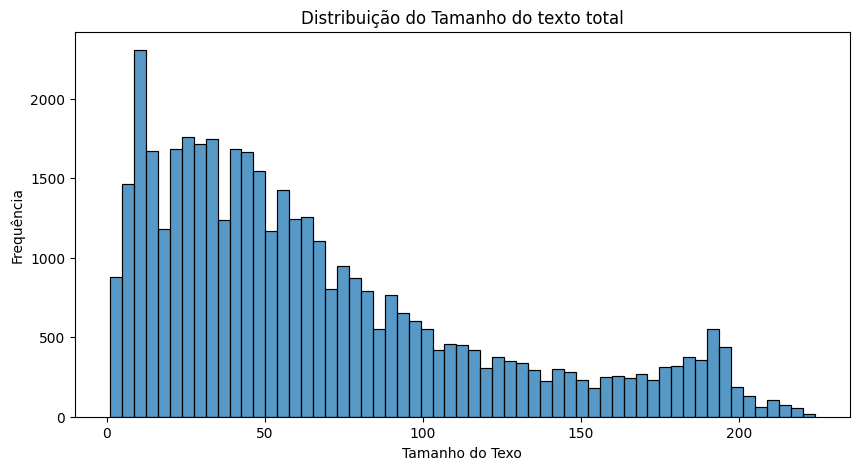

In [37]:
plt.figure(figsize=(10,5))
sns.histplot(data=df_filtered, x='len_clean_text')
plt.title('Distribuição do Tamanho do texto total')
plt.xlabel('Tamanho do Texo')
plt.ylabel('Frequência')
plt.show()

#### 2.2.2) Distribuição por Nota

Ao avaliar a volumetria por nota, percebe-se que há uma distribuição bem desigual, especialemnte entre as notas 1 e 5, portanto o ideal seria mapear as notas para suas classificações ('Positiva' - 4,5; Neutra - 3; 'Negativa' - 1,2)

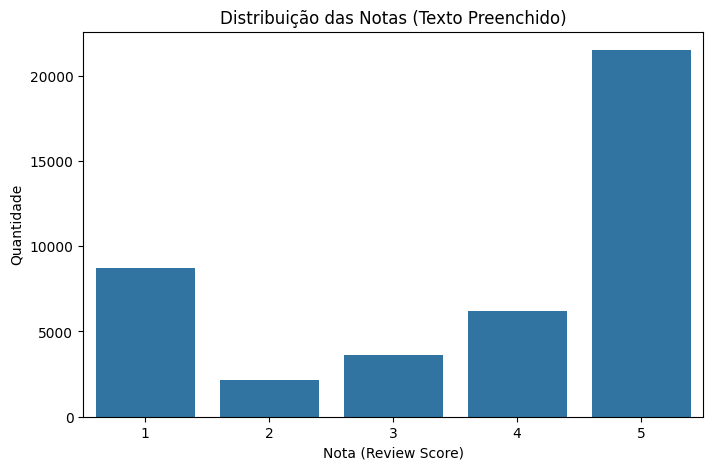

In [38]:
plt.figure(figsize=(8,5))
sns.countplot(data=df_filtered, x='review_score')
plt.title('Distribuição das Notas (Texto Preenchido)')
plt.xlabel('Nota (Review Score)')
plt.ylabel('Quantidade')
plt.show()

In [39]:
df_filtered['review_score_adapted'] = df_filtered['review_score'].apply(lambda s: 
                                                                            'Negativo' if s <= 2 else 
                                                                            'Positivo' if s >= 4 else 'Neutro'
                                                                        )

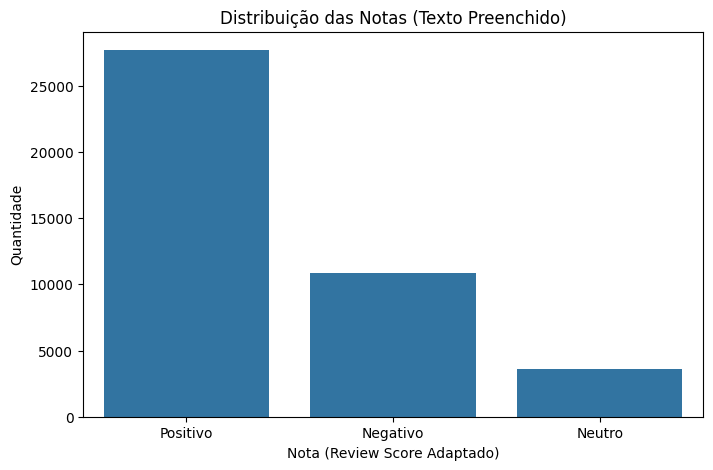

In [40]:
# Distribuição das notas classificadas

plt.figure(figsize=(8,5))
sns.countplot(data=df_filtered, x='review_score_adapted')
plt.title('Distribuição das Notas (Texto Preenchido)')
plt.xlabel('Nota (Review Score Adaptado)')
plt.ylabel('Quantidade')
plt.show()

In [47]:
# Avaliação de conflitos de rótulo

df_conflicts = (
    df_filtered.groupby('clean_text')['review_score_adapted']\
    .agg(['nunique', 'count'])\
    .query('nunique > 1')
    .sort_values(by='count', ascending=False)
)

display(df_conflicts.head())

,nunique,count
clean_text,,
muito bom,3,568
recomendo,3,424
bom,3,412
ótimo,3,306
excelente,3,268


In [49]:
df_filtered[df_filtered['len_clean_text'] <= 2][['clean_text', 'len_clean_text', 'review_score', 'review_score_adapted']]

,clean_text,len_clean_text,review_score,review_score_adapted
160,ok,2,5,Positivo
297,a,1,5,Positivo
812,na,2,5,Positivo
2383,a,1,1,Negativo
2434,ok,2,5,Positivo
3306,ok,2,5,Positivo
4522,ok,2,5,Positivo
4589,nc,2,5,Positivo
5374,ok,2,4,Positivo
6036,ok,2,5,Positivo


#### 2.2.3) Avaliação da Volumetria do Texto

In [ ]:
# Avaliação de frequência de expressões repetidas
display(df_filtered['clean_text'].value_counts().head(30))

clean_text
muito bom                     568
recomendo                     424
bom                           412
ótimo                         306
excelente                     268
otimo                         260
super recomendo               155
ok                            130
boa                           118
tudo ok                       111
ótimo produto                 107
não recebi o produto           82
tudo certo                     80
gostei                         77
ótima                          74
bom produto                    71
gostei muito                   58
entrega rápida                 58
adorei                         56
chegou antes do prazo          56
perfeito                       49
otima                          48
nota                           47
muito boa                      45
bom bom                        42
excelente produto              42
ainda não recebi o produto     40
tudo perfeito                  37
produto muito bom              37
sat

In [ ]:
# Identificão de Possíveis problemas

df_filtered['has_url'] = df_filtered['full_text'].str.contains(r'http|www', case=False, na=False)
df_filtered['has_html'] = df_filtered['full_text'].str.contains(r'<.*?>', regex=True, na=False)
df_filtered['has_number'] =  df_filtered['full_text'].str.contains(r'\d', regex=True, na=False)
df_filtered['has_break'] = df_filtered['full_text'].str.contains(r'\\r|\\n|\r|\n', regex=True, na=False)

print(df_filtered[['has_url','has_html','has_number','has_break']].mean().round(4))

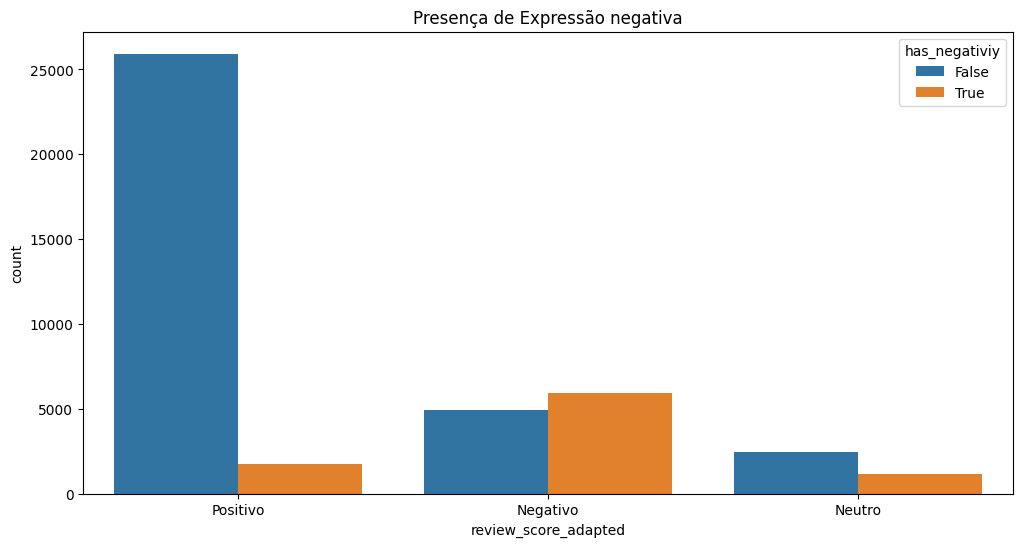

In [43]:
df_filtered['has_negativiy'] = df_filtered['clean_text'].str.contains(r'\bnão\b|\bnunca\b|\bjamais\b', regex=True)

plt.figure(figsize=(12,6))
sns.countplot(data=df_filtered, x='review_score_adapted', hue='has_negativiy')
plt.title("Presença de Expressão negativa")
plt.show()

#### 2.2.4) Distribuição

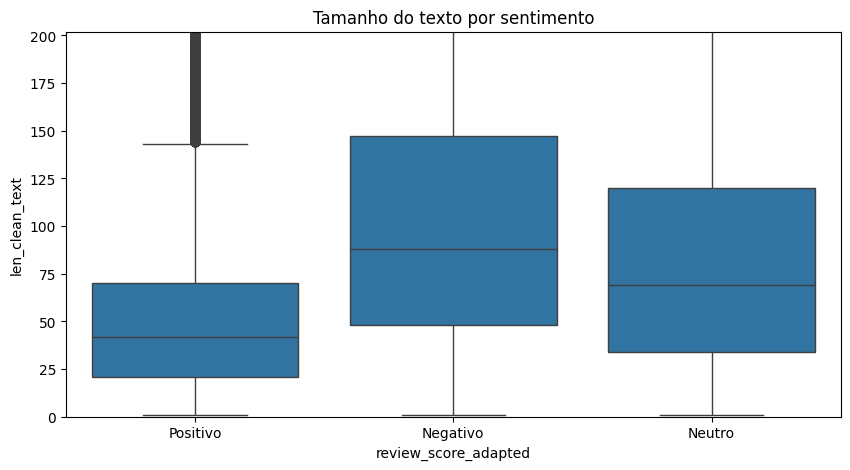

In [52]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df_filtered, x='review_score_adapted', y='len_clean_text')
plt.ylim(0, df_filtered['len_clean_text'].quantile(0.99))
plt.title('Tamanho do texto por sentimento')
plt.show()